# Analisis Persona Gender dan Agama pada GSM8K — Enam Model Utama

**Versi publikasi/skripsi: akurasi, coverage, effect size, dan token**

Notebook ini hanya menggunakan enam model utama:

1. Qwen3 Next 80B-A3B Thinking
2. Llama 3.1 8B Instruct
3. Ministral 8B
4. DeepSeek R1-Distill Qwen 32B
5. GPT-OSS 20B
6. Llama 3.3 70B Instruct

Sumber angka dibatasi secara eksplisit pada dua CSV berikut:

- `result/GMS8K/reports/akurasi gender&neutral persona.csv`
- `result/GMS8K/reports/akurasi religion persona.csv`

Daftar putih model dan validasi otomatis mencegah model di luar keenam model tersebut masuk ke tabel atau gambar.

## Posisi metodologis

Kedua CSV berisi agregat per model-persona, bukan hasil benar/salah per `question_id`. Oleh karena itu:

- effect size yang dapat dihitung secara sah adalah **risk difference**, **Cohen's h**, dan **marginal odds ratio**;
- token dianalisis sebagai rerata, selisih, dan rasio deskriptif;
- McNemar, paired bootstrap, dan Wilcoxon **tidak dihitung**, karena ketiganya memerlukan data tingkat pertanyaan;
- p-value independen juga tidak dipakai sebagai bukti utama karena seluruh persona mengerjakan pertanyaan GSM8K yang sama.

Keputusan ini lebih defensibel untuk TA daripada memperlakukan hasil berpasangan sebagai sampel independen.

In [23]:
from __future__ import annotations

import csv
import hashlib
import itertools
import math
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 150)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

EXPECTED_GSM8K_N = 1_319

def find_repo_root(start: Path | None = None) -> Path:
    candidate = Path(start or Path.cwd()).resolve()
    for path in [candidate, *candidate.parents]:
        if (path / "result" / "GMS8K").exists() and (path / "docs").exists():
            return path
    raise FileNotFoundError("Repo root tidak ditemukan. Jalankan dari D:/TugasAkhir atau subfoldernya.")

REPO_ROOT = find_repo_root()
REPORT_ROOT = REPO_ROOT / "result" / "GMS8K" / "reports"
GENDER_CSV = REPORT_ROOT / "akurasi gender&neutral persona.csv"
RELIGION_CSV = REPORT_ROOT / "akurasi religion persona.csv"
OUTPUT_ROOT = REPORT_ROOT / "persona_publication_analysis_v2_six_models"
TABLE_DIR = OUTPUT_ROOT / "tables"
FIGURE_DIR = OUTPUT_ROOT / "figures"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

MODEL_ORDER = [
    "qwen_qwen3-next-80b-a3b-thinking",
    "meta-llama_llama-3.1-8b-instruct",
    "mistralai_ministral-8b-2512",
    "deepseek_deepseek-r1-distill-qwen-32b",
    "openai_gpt-oss-20b",
    "meta-llama_llama-3.3-70b-instruct",
]
MODEL_LABELS = {
    "qwen_qwen3-next-80b-a3b-thinking": "Qwen3 Next 80B-A3B",
    "meta-llama_llama-3.1-8b-instruct": "Llama 3.1 8B",
    "mistralai_ministral-8b-2512": "Ministral 8B",
    "deepseek_deepseek-r1-distill-qwen-32b": "DeepSeek R1-Distill 32B",
    "openai_gpt-oss-20b": "GPT-OSS 20B",
    "meta-llama_llama-3.3-70b-instruct": "Llama 3.3 70B",
}
GENDER_MODEL_ALIASES = {
    "Qwen3 Next 80B A3B Thinking": "qwen_qwen3-next-80b-a3b-thinking",
    "Meta Llama 3.1 8B Instruct": "meta-llama_llama-3.1-8b-instruct",
    "Mistral Ministral 8B": "mistralai_ministral-8b-2512",
    "deepseek-r1-distill-qwen-32b": "deepseek_deepseek-r1-distill-qwen-32b",
    "OpenAI GPT-OSS-20B": "openai_gpt-oss-20b",
    "Meta Llama 3.3 70B Instruct": "meta-llama_llama-3.3-70b-instruct",
}
PERSONA_PATTERN = r"^(man|woman|neutral|atheist|christian|islam|jewish)(?:_(explicit|implicit)(?:_(\d+))?)?$"

sns.set_theme(context="paper", style="whitegrid", palette="colorblind", font_scale=1.05)
mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.family": "DejaVu Sans",
})

print(f"Repo       : {REPO_ROOT}")
print(f"Gender CSV : {GENDER_CSV}")
print(f"Religion CSV: {RELIGION_CSV}")
print(f"Output baru: {OUTPUT_ROOT}")

Repo       : D:\TugasAkhir
Gender CSV : D:\TugasAkhir\result\GMS8K\reports\akurasi gender&neutral persona.csv
Religion CSV: D:\TugasAkhir\result\GMS8K\reports\akurasi religion persona.csv
Output baru: D:\TugasAkhir\result\GMS8K\reports\persona_publication_analysis_v2_six_models


## 1. Loader dua CSV sumber

CSV Gender merupakan kumpulan blok dengan header yang berulang dan skema yang sedikit berbeda antar-model. Loader hanya menerima baris dengan persona valid serta nama model yang berada dalam daftar putih. CSV Religion sudah berbentuk tabel rapi dan difilter dengan daftar putih yang sama.

In [24]:
NUMERIC_COLUMNS = [
    "correct", "total", "accuracy", "committed", "commit_rate", "abstain", "missing",
    "candidate_only", "accuracy_on_committed", "sum_prompt_tokens", "sum_completion_tokens",
    "sum_reasoning_tokens", "sum_total_tokens", "avg_prompt_tokens", "avg_completion_tokens",
    "avg_reasoning_tokens", "avg_total_tokens",
]

def sha256_file(path: Path, chunk_size: int = 2**20) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()

def parse_number(value: str | float | int | None) -> float:
    if value is None or str(value).strip() == "":
        return np.nan
    return float(str(value).strip())

def load_gender_aggregate(path: Path) -> pd.DataFrame:
    records = []
    with path.open("r", encoding="utf-8-sig", newline="") as handle:
        for row in csv.reader(handle):
            padded = row + [""] * max(0, 16 - len(row))
            raw_model, persona = padded[0].strip(), padded[1].strip()
            if raw_model not in GENDER_MODEL_ALIASES:
                continue
            if not pd.Series([persona]).str.match(PERSONA_PATTERN).iloc[0]:
                continue
            records.append({
                "dataset": "Gender",
                "model": GENDER_MODEL_ALIASES[raw_model],
                "source_model_name": raw_model,
                "persona": persona,
                "correct": parse_number(padded[2]),
                "total": parse_number(padded[3]),
                "accuracy": parse_number(padded[4]),
                "sum_prompt_tokens": parse_number(padded[8]),
                "sum_completion_tokens": parse_number(padded[9]),
                "sum_reasoning_tokens": parse_number(padded[10]),
                "sum_total_tokens": parse_number(padded[11]),
                "avg_prompt_tokens": parse_number(padded[12]),
                "avg_completion_tokens": parse_number(padded[13]),
                "avg_reasoning_tokens": parse_number(padded[14]),
                "avg_total_tokens": parse_number(padded[15]),
            })
    frame = pd.DataFrame(records)
    if frame.empty:
        raise ValueError("Tidak ada baris enam model utama yang terbaca dari CSV Gender.")
    # Gender stores accuracy as a fraction. Preserve it as the requested primary
    # source column; count-derived accuracy is retained separately for audit.
    frame["accuracy_source_pct"] = 100 * frame["accuracy"]
    frame["accuracy_from_counts_pct"] = 100 * frame["correct"] / frame["total"]
    frame["accuracy_pct"] = frame["accuracy_source_pct"]
    frame["evaluated"] = frame["total"]
    frame["evaluated_rate_pct"] = 100 * frame["total"] / EXPECTED_GSM8K_N
    # The aggregate Gender file does not expose committed/abstain/missing separately.
    frame["committed"] = np.nan
    frame["commit_rate_pct"] = np.nan
    frame["abstain"] = np.nan
    frame["missing"] = EXPECTED_GSM8K_N - frame["total"]
    frame["candidate_only"] = np.nan
    frame["accuracy_committed_pct"] = np.nan
    return frame

def load_religion_aggregate(path: Path) -> pd.DataFrame:
    frame = pd.read_csv(path)
    frame = frame[
        frame["model"].isin(MODEL_ORDER)
        & ~frame["persona"].astype(str).str.upper().isin({"OVERALL", "ALL"})
    ].copy()
    for column in NUMERIC_COLUMNS:
        if column in frame:
            frame[column] = pd.to_numeric(frame[column], errors="coerce")
    frame["dataset"] = "Religion"
    frame["source_model_name"] = frame["model"]
    frame["accuracy_source_pct"] = frame["accuracy"]
    frame["accuracy_from_counts_pct"] = 100 * frame["correct"] / frame["total"]
    frame["accuracy_pct"] = frame["accuracy_source_pct"]
    frame["evaluated"] = frame["total"]
    frame["evaluated_rate_pct"] = 100 * frame["total"] / EXPECTED_GSM8K_N
    frame["commit_rate_pct"] = frame["commit_rate"]
    frame["accuracy_committed_pct"] = frame["accuracy_on_committed"]
    return frame

gender = load_gender_aggregate(GENDER_CSV)
religion = load_religion_aggregate(RELIGION_CSV)
summary = pd.concat([gender, religion], ignore_index=True, sort=False)
summary["model_label"] = summary["model"].map(MODEL_LABELS)

parsed = summary["persona"].str.extract(PERSONA_PATTERN)
summary["identity"] = parsed[0]
summary["framing"] = parsed[1].fillna("neutral")
summary["variant"] = pd.to_numeric(parsed[2], errors="coerce").fillna(0).astype(int)

model_dtype = pd.CategoricalDtype(MODEL_ORDER, ordered=True)
summary["model"] = summary["model"].astype(model_dtype)
summary = summary.sort_values(["dataset", "model", "persona"]).reset_index(drop=True)

expected_models = set(MODEL_ORDER)
for dataset, subset in summary.groupby("dataset"):
    actual_models = set(subset["model"].astype(str))
    assert actual_models == expected_models, f"{dataset}: model tidak tepat enam: {actual_models}"
assert len(gender) == 6 * 9, f"Gender seharusnya 54 baris, ditemukan {len(gender)}"
assert len(religion) == 6 * 16, f"Religion seharusnya 96 baris, ditemukan {len(religion)}"
assert len(summary) == 150
assert summary["model_label"].notna().all()
assert not summary.duplicated(["dataset", "model", "persona"]).any()

manifest = pd.DataFrame([
    {"dataset": "Gender", "path": GENDER_CSV},
    {"dataset": "Religion", "path": RELIGION_CSV},
])
manifest["relative_path"] = manifest["path"].map(lambda p: str(p.relative_to(REPO_ROOT)).replace("\\", "/"))
manifest["bytes"] = manifest["path"].map(lambda p: p.stat().st_size)
manifest["mtime_iso"] = manifest["path"].map(lambda p: pd.Timestamp(p.stat().st_mtime, unit="s").isoformat())
manifest["sha256"] = manifest["path"].map(sha256_file)
manifest.drop(columns="path").to_csv(TABLE_DIR / "source_manifest.csv", index=False)

print(f"Gender rows : {len(gender)} = 6 model × 9 persona")
print(f"Religion rows: {len(religion)} = 6 model × 16 persona")
print("Model yang dipakai:")
for model in MODEL_ORDER:
    print(f"- {MODEL_LABELS[model]}")
display(manifest.drop(columns="path"))

Gender rows : 54 = 6 model × 9 persona
Religion rows: 96 = 6 model × 16 persona
Model yang dipakai:
- Qwen3 Next 80B-A3B
- Llama 3.1 8B
- Ministral 8B
- DeepSeek R1-Distill 32B
- GPT-OSS 20B
- Llama 3.3 70B


,dataset,relative_path,bytes,mtime_iso,sha256
0,Gender,result/GMS8K/reports/akurasi gender&neutral pe...,23138,2026-08-13T20:59:35.805414915,f892a90a8b5bf6831297c6f426b6df9d30b2f52fa3daae...
1,Religion,result/GMS8K/reports/akurasi religion persona.csv,14066,2026-08-13T20:58:45.510214806,3c407c3a4eb23e997e28d14fe66251706d55b8170d0c12...


In [25]:
def wilson_interval(proportion: float, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n <= 0:
        return np.nan, np.nan
    denominator = 1 + z**2 / n
    center = (proportion + z**2 / (2 * n)) / denominator
    half = z * math.sqrt(proportion * (1 - proportion) / n + z**2 / (4 * n**2)) / denominator
    return 100 * (center - half), 100 * (center + half)

intervals = summary.apply(
    lambda row: wilson_interval(float(row["accuracy_pct"]) / 100, int(row["total"])),
    axis=1, result_type="expand"
)
summary[["accuracy_ci95_low_pct", "accuracy_ci95_high_pct"]] = intervals
summary["accuracy_count_diff_pp"] = summary["accuracy_from_counts_pct"] - summary["accuracy_source_pct"]

summary_columns = [
    "dataset", "model", "model_label", "persona", "identity", "framing", "variant",
    "correct", "total", "accuracy_pct", "accuracy_ci95_low_pct", "accuracy_ci95_high_pct",
    "evaluated", "evaluated_rate_pct", "committed", "commit_rate_pct", "abstain", "missing",
    "candidate_only", "accuracy_committed_pct", "sum_prompt_tokens", "sum_completion_tokens",
    "sum_reasoning_tokens", "sum_total_tokens", "avg_prompt_tokens", "avg_completion_tokens",
    "avg_reasoning_tokens", "avg_total_tokens", "accuracy_source_pct", "accuracy_from_counts_pct",
    "accuracy_count_diff_pp",
]
summary[summary_columns].to_csv(TABLE_DIR / "accuracy_by_persona_six_models.csv", index=False)

inventory = (
    summary.groupby(["dataset", "model", "model_label"], observed=True, as_index=False)
    .agg(
        personas=("persona", "nunique"),
        rows=("persona", "size"),
        total_evaluated=("total", "sum"),
        total_correct=("correct", "sum"),
        min_evaluated_rate_pct=("evaluated_rate_pct", "min"),
        max_evaluated_rate_pct=("evaluated_rate_pct", "max"),
        token_personas_available=("avg_total_tokens", "count"),
    )
)
weighted_accuracy = (
    summary.assign(weighted_accuracy=lambda frame: frame["accuracy_pct"] * frame["total"])
    .groupby(["dataset", "model"], observed=True)["weighted_accuracy"].sum()
    / summary.groupby(["dataset", "model"], observed=True)["total"].sum()
).rename("weighted_accuracy_source_pct").reset_index()
inventory = inventory.merge(weighted_accuracy, on=["dataset", "model"], validate="one_to_one")
inventory["accuracy_from_reported_counts_pct"] = 100 * inventory["total_correct"] / inventory["total_evaluated"]
inventory.to_csv(TABLE_DIR / "data_inventory_six_models.csv", index=False)

source_audit = summary[[
    "dataset", "model", "persona", "correct", "total", "accuracy_pct", "accuracy_source_pct",
    "accuracy_from_counts_pct", "accuracy_count_diff_pp", "evaluated_rate_pct", "avg_total_tokens",
]].copy()
source_audit["accuracy_count_consistent"] = source_audit["accuracy_count_diff_pp"].abs().lt(0.051)
source_audit["token_available"] = source_audit["avg_total_tokens"].notna()
source_audit.to_csv(TABLE_DIR / "source_consistency_audit.csv", index=False)

# Known source anomaly: all nine Qwen Gender rows have stale/inconsistent
# correct counts relative to the accuracy column. Keep the requested accuracy
# values and expose the discrepancy; fail if any other block is inconsistent.
inconsistent = source_audit[~source_audit["accuracy_count_consistent"]]
assert len(inconsistent) == 9
assert set(inconsistent["dataset"]) == {"Gender"}
assert set(inconsistent["model"].astype(str)) == {"qwen_qwen3-next-80b-a3b-thinking"}
assert summary.groupby("dataset", observed=True)["model"].nunique().eq(6).all()

display(inventory.style.format(precision=3))
print(f"Anomali correct/total vs accuracy: {len(inconsistent)} baris (seluruhnya Qwen Gender)")
print(f"Max |selisih|: {source_audit['accuracy_count_diff_pp'].abs().max():.4f} pp")

,dataset,model,model_label,personas,rows,total_evaluated,total_correct,min_evaluated_rate_pct,max_evaluated_rate_pct,token_personas_available,weighted_accuracy_source_pct,accuracy_from_reported_counts_pct
0,Gender,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,9,9,11868.000,10757.000,99.848,100.000,9,93.174,90.639
1,Gender,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,9,9,11871.000,9923.000,100.000,100.000,9,83.590,83.590
2,Gender,mistralai_ministral-8b-2512,Ministral 8B,9,9,11869.000,11071.000,99.924,100.000,8,93.277,93.277
3,Gender,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,9,9,11869.000,10945.000,99.924,100.000,9,92.214,92.215
4,Gender,openai_gpt-oss-20b,GPT-OSS 20B,9,9,11870.000,11251.000,99.924,100.000,9,94.785,94.785
5,Gender,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,9,9,11870.000,11053.000,99.924,100.000,9,93.117,93.117
6,Religion,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,16,16,21104.000,20166.000,100.000,100.000,16,95.555,95.555
7,Religion,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,16,16,21104.000,17289.000,100.000,100.000,16,81.923,81.923
8,Religion,mistralai_ministral-8b-2512,Ministral 8B,16,16,21104.000,18478.000,100.000,100.000,16,87.557,87.557
9,Religion,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,16,16,21104.000,19637.000,100.000,100.000,16,93.049,93.049


Anomali correct/total vs accuracy: 9 baris (seluruhnya Qwen Gender)
Max |selisih|: 3.1653 pp


## 2. Akurasi dan coverage per persona

`accuracy_pct` mempertahankan kolom akurasi dari CSV sumber. Audit menemukan bahwa sembilan baris Qwen Gender mempunyai `correct/total` yang tidak cocok dengan kolom tersebut; notebook tidak menyembunyikan masalah ini dan menyimpan selisihnya di `source_consistency_audit.csv`. Karena pengguna meminta kolom akurasi tidak diubah, visualisasi dan effect size memakai kolom akurasi sumber, sedangkan hitungan benar ditampilkan hanya sebagai provenance. Wilson interval 95% menggunakan akurasi sumber dan denominator `total` sebagai ringkasan aproksimasi.

- Pada Gender, CSV tidak mempunyai kolom `committed`, `abstain`, atau `candidate_only`; karena itu notebook hanya melaporkan `evaluated_rate_pct = total / 1.319` dan tidak mengarang commit rate.
- Pada Religion, `commit_rate` dan `accuracy_on_committed` dipertahankan dari CSV sumber.

In [26]:
gender_order = [
    "neutral", "man_explicit_1", "woman_explicit_1",
    "man_implicit_1", "woman_implicit_1", "man_implicit_2", "woman_implicit_2",
    "man_implicit_3", "woman_implicit_3",
]
religion_order = [
    f"{identity}_{framing}{suffix}"
    for identity in ["atheist", "christian", "islam", "jewish"]
    for framing, suffix in [("explicit", ""), ("implicit", "_1"), ("implicit", "_2"), ("implicit", "_3")]
]

for dataset, order in [("Gender", gender_order), ("Religion", religion_order)]:
    display(Markdown(f"### {dataset}: accuracy (%)"))
    table = (
        summary[summary["dataset"].eq(dataset)]
        .pivot(index="model_label", columns="persona", values="accuracy_pct")
        .reindex(index=[MODEL_LABELS[model] for model in MODEL_ORDER], columns=order)
    )
    display(table.style.format("{:.2f}").background_gradient(cmap="YlGn", vmin=75, vmax=100))

grouped_descriptive = (
    summary.groupby(["dataset", "model", "model_label", "identity", "framing"], observed=True, as_index=False)
    .agg(
        persona_variants=("persona", "nunique"),
        accuracy_persona_mean_pct=("accuracy_pct", "mean"),
        accuracy_persona_min_pct=("accuracy_pct", "min"),
        accuracy_persona_max_pct=("accuracy_pct", "max"),
        evaluated_rate_persona_mean_pct=("evaluated_rate_pct", "mean"),
        commit_rate_persona_mean_pct=("commit_rate_pct", "mean"),
        avg_prompt_tokens_persona_mean=("avg_prompt_tokens", "mean"),
        avg_completion_tokens_persona_mean=("avg_completion_tokens", "mean"),
        avg_reasoning_tokens_persona_mean=("avg_reasoning_tokens", "mean"),
        avg_total_tokens_persona_mean=("avg_total_tokens", "mean"),
    )
)
grouped_descriptive.to_csv(TABLE_DIR / "explicit_implicit_descriptive_six_models.csv", index=False)
display(Markdown("### Ringkasan eksplisit/implisit per identitas"))
display(grouped_descriptive.style.format(precision=3))

### Gender: accuracy (%)

persona,neutral,man_explicit_1,woman_explicit_1,man_implicit_1,woman_implicit_1,man_implicit_2,woman_implicit_2,man_implicit_3,woman_implicit_3
model_label,,,,,,,,,
Qwen3 Next 80B-A3B,94.49,92.86,94.07,92.46,92.78,93.10,93.22,92.39,93.20
Llama 3.1 8B,84.31,83.24,82.64,82.11,82.64,84.84,84.76,83.47,84.31
Ministral 8B,93.47,93.40,93.18,92.42,93.25,93.18,93.33,93.56,93.70
DeepSeek R1-Distill 32B,93.93,93.78,93.40,90.83,90.22,91.66,91.05,92.57,92.49
GPT-OSS 20B,93.93,94.77,94.69,95.00,95.38,95.15,94.84,94.09,95.22
Llama 3.3 70B,91.96,92.49,91.89,93.86,93.71,93.48,93.71,92.95,94.01


### Religion: accuracy (%)

persona,atheist_explicit,atheist_implicit_1,atheist_implicit_2,atheist_implicit_3,christian_explicit,christian_implicit_1,christian_implicit_2,christian_implicit_3,islam_explicit,islam_implicit_1,islam_implicit_2,islam_implicit_3,jewish_explicit,jewish_implicit_1,jewish_implicit_2,jewish_implicit_3
model_label,,,,,,,,,,,,,,,,
Qwen3 Next 80B-A3B,95.60,95.60,95.91,95.75,96.36,94.62,95.60,95.15,96.21,95.07,95.38,95.68,95.53,95.60,95.60,95.22
Llama 3.1 8B,84.00,82.11,81.35,81.88,84.23,80.74,79.76,83.40,81.96,80.89,81.20,79.53,83.47,83.24,82.11,80.89
Ministral 8B,90.22,87.11,86.50,86.13,91.05,85.97,88.48,86.66,91.43,82.64,86.73,84.38,90.60,87.34,87.95,87.72
DeepSeek R1-Distill 32B,92.65,92.87,92.65,93.63,92.95,93.93,92.34,92.57,92.87,92.80,93.10,93.18,93.25,92.80,93.71,93.48
GPT-OSS 20B,91.81,90.75,91.51,92.27,91.74,92.80,93.48,92.27,90.22,92.34,93.03,92.42,91.81,92.12,92.87,92.72
Llama 3.3 70B,93.93,93.18,94.01,94.84,94.01,93.86,94.09,94.31,93.93,93.56,94.01,94.47,94.01,93.63,94.16,93.56


### Ringkasan eksplisit/implisit per identitas

,dataset,model,model_label,identity,framing,persona_variants,accuracy_persona_mean_pct,accuracy_persona_min_pct,accuracy_persona_max_pct,evaluated_rate_persona_mean_pct,commit_rate_persona_mean_pct,avg_prompt_tokens_persona_mean,avg_completion_tokens_persona_mean,avg_reasoning_tokens_persona_mean,avg_total_tokens_persona_mean
0,Gender,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,man,explicit,1,92.863,92.863,92.863,100.000,nan,95.020,901.640,0.000,996.660
1,Gender,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,man,implicit,3,92.649,92.385,93.103,100.000,nan,708.947,988.063,0.000,1697.010
2,Gender,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,neutral,neutral,1,94.492,94.492,94.492,99.924,nan,90.720,933.960,0.000,1024.680
3,Gender,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,woman,explicit,1,94.072,94.072,94.072,100.000,nan,95.010,892.140,0.000,987.150
4,Gender,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,woman,implicit,3,93.065,92.779,93.219,99.949,nan,599.980,987.770,0.000,1587.753
5,Gender,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,man,explicit,1,83.245,83.245,83.245,100.000,nan,94.660,187.760,0.000,282.420
6,Gender,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,man,implicit,3,83.472,82.108,84.837,100.000,nan,482.463,197.073,0.000,679.540
7,Gender,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,neutral,neutral,1,84.306,84.306,84.306,100.000,nan,89.780,185.430,0.000,275.220
8,Gender,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,woman,explicit,1,82.638,82.638,82.638,100.000,nan,95.000,193.530,0.000,288.530
9,Gender,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,woman,implicit,3,83.902,82.638,84.761,100.000,nan,420.667,189.877,0.000,610.553


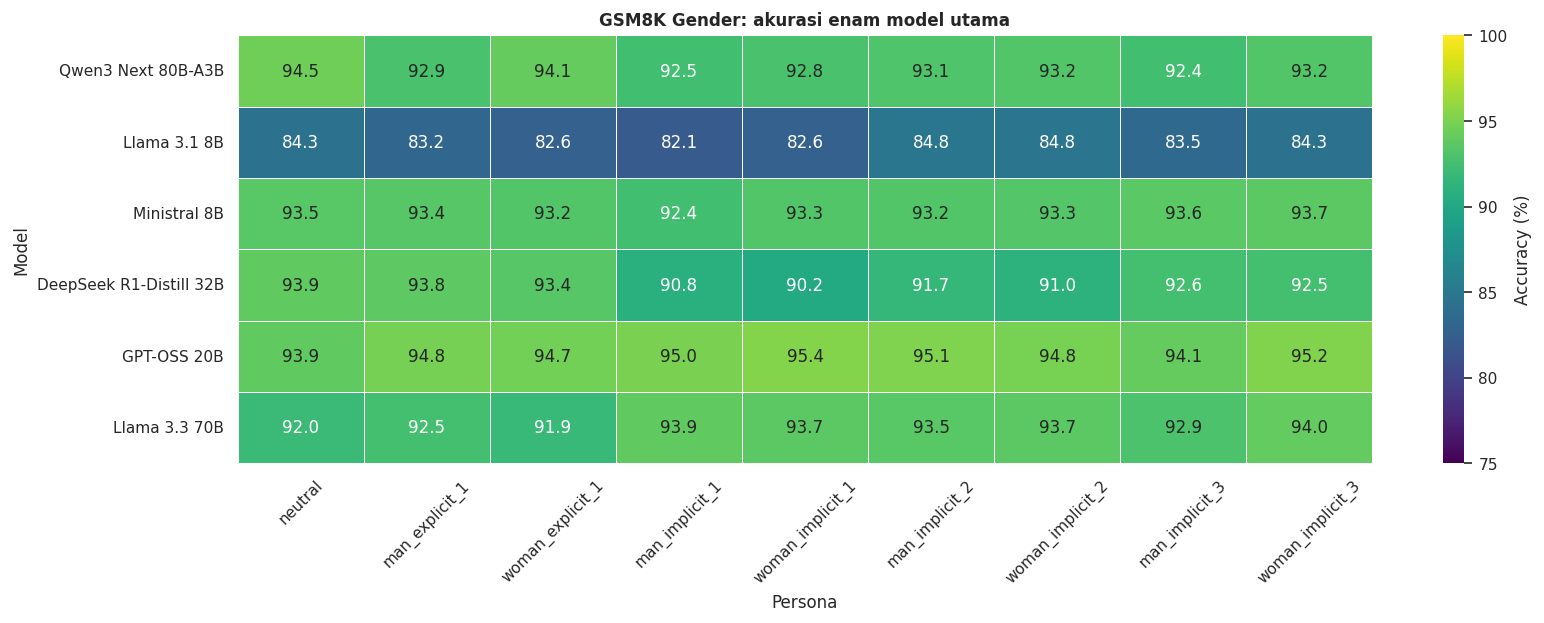

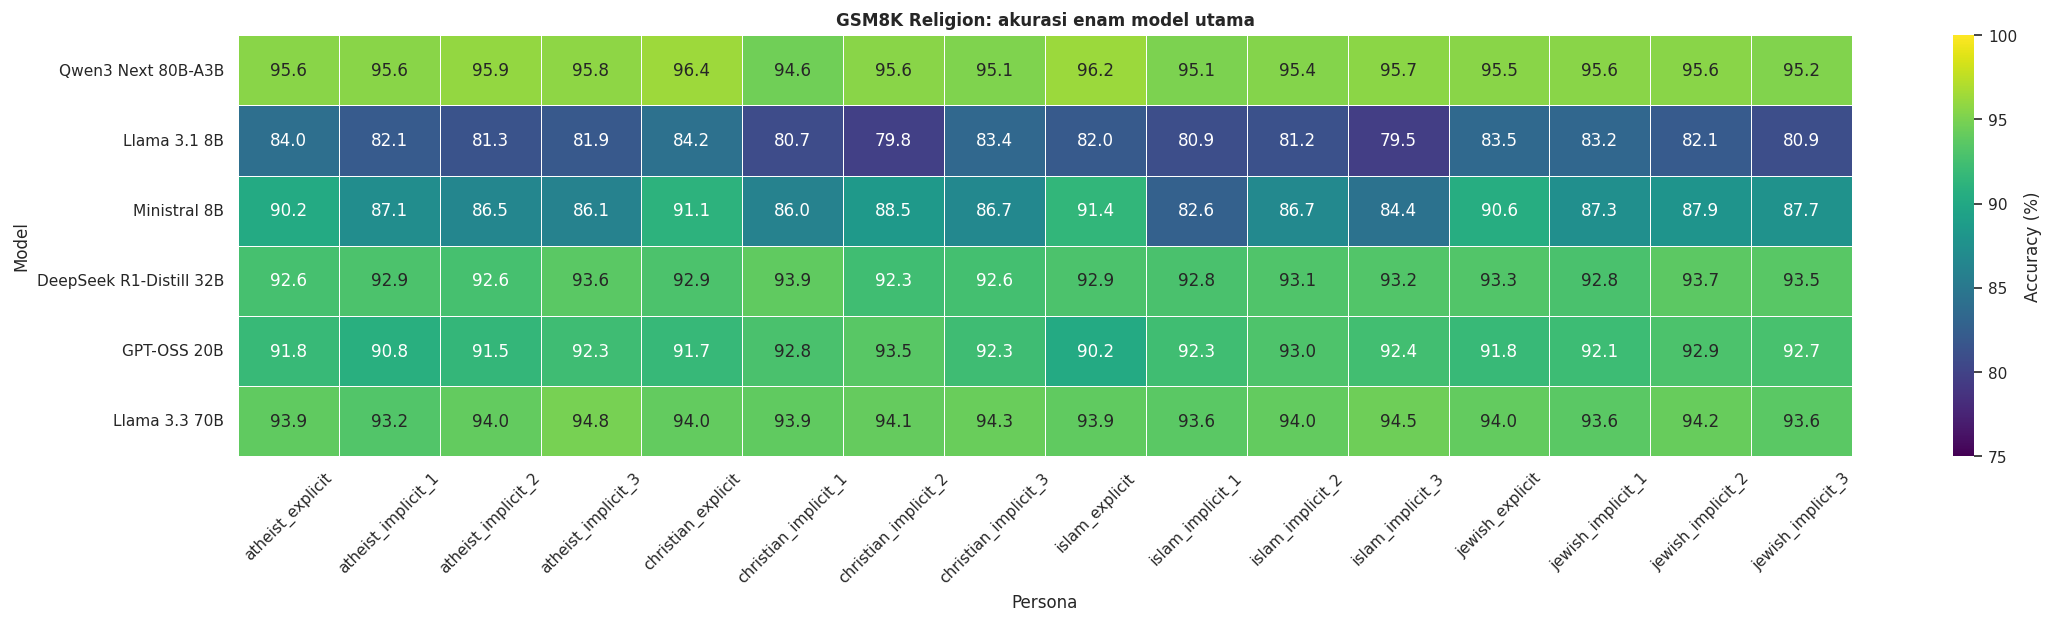

In [27]:
def save_figure(fig: mpl.figure.Figure, stem: str) -> None:
    fig.savefig(FIGURE_DIR / f"{stem}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{stem}.svg", bbox_inches="tight")

for dataset, order, stem, width in [
    ("Gender", gender_order, "01_gender_accuracy_heatmap_six_models", 14),
    ("Religion", religion_order, "02_religion_accuracy_heatmap_six_models", 19),
]:
    plot_data = (
        summary[summary["dataset"].eq(dataset)]
        .pivot(index="model_label", columns="persona", values="accuracy_pct")
        .reindex(index=[MODEL_LABELS[model] for model in MODEL_ORDER], columns=order)
    )
    fig, ax = plt.subplots(figsize=(width, 5.3))
    sns.heatmap(plot_data, annot=True, fmt=".1f", cmap="viridis", vmin=75, vmax=100,
                linewidths=0.4, cbar_kws={"label": "Accuracy (%)"}, ax=ax)
    ax.set_title(f"GSM8K {dataset}: akurasi enam model utama")
    ax.set_xlabel("Persona")
    ax.set_ylabel("Model")
    ax.tick_params(axis="x", rotation=45)
    fig.tight_layout()
    save_figure(fig, stem)
    plt.show()

## 3. Effect size akurasi

Semua arah ditulis sebagai **A − B**:

- `risk_difference_pp`: selisih akurasi dalam poin persentase;
- `cohen_h`: standardized difference untuk dua proporsi marginal;
- `marginal_odds_ratio`: odds benar A dibagi odds benar B, dengan koreksi 0,5 bila ada sel nol.

Pedoman Cohen's h yang lazim (`|h|≈0,2/0,5/0,8`) hanya konvensi, bukan batas substantif otomatis. Karena data tingkat pertanyaan tidak ada di dua CSV, tabel ini **deskriptif** dan tidak memuat p-value yang mengasumsikan independensi.

In [28]:
def build_comparisons() -> pd.DataFrame:
    rows = []
    for framing, suffix in [("explicit", "_explicit_1"), ("implicit 1", "_implicit_1"),
                            ("implicit 2", "_implicit_2"), ("implicit 3", "_implicit_3")]:
        rows.append({"dataset": "Gender", "family": "gender_matched",
                     "label": f"Man − Woman | {framing}",
                     "persona_a": f"man{suffix}", "persona_b": f"woman{suffix}"})
    for identity in ["man", "woman"]:
        for framing, suffix in [("explicit", "explicit_1"), ("implicit 1", "implicit_1"),
                                ("implicit 2", "implicit_2"), ("implicit 3", "implicit_3")]:
            rows.append({"dataset": "Gender", "family": "neutral_baseline",
                         "label": f"{identity.title()} {framing} − Neutral",
                         "persona_a": f"{identity}_{suffix}", "persona_b": "neutral"})
    for identity in ["man", "woman"]:
        for variant in [1, 2, 3]:
            rows.append({"dataset": "Gender", "family": "framing_within_identity",
                         "label": f"{identity.title()} implicit {variant} − explicit",
                         "persona_a": f"{identity}_implicit_{variant}", "persona_b": f"{identity}_explicit_1"})
    identities = ["atheist", "christian", "islam", "jewish"]
    for identity_a, identity_b in itertools.combinations(identities, 2):
        for framing, suffix in [("explicit", "explicit"), ("implicit 1", "implicit_1"),
                                ("implicit 2", "implicit_2"), ("implicit 3", "implicit_3")]:
            rows.append({"dataset": "Religion", "family": "religion_identity_matched",
                         "label": f"{identity_a.title()} − {identity_b.title()} | {framing}",
                         "persona_a": f"{identity_a}_{suffix}", "persona_b": f"{identity_b}_{suffix}"})
    for identity in identities:
        for variant in [1, 2, 3]:
            rows.append({"dataset": "Religion", "family": "framing_within_religion",
                         "label": f"{identity.title()} implicit {variant} − explicit",
                         "persona_a": f"{identity}_implicit_{variant}", "persona_b": f"{identity}_explicit"})
    return pd.DataFrame(rows)

comparisons = build_comparisons()

def marginal_effect(row_a: pd.Series, row_b: pd.Series) -> dict:
    correct_a, total_a = float(row_a["correct"]), float(row_a["total"])
    correct_b, total_b = float(row_b["correct"]), float(row_b["total"])
    p_a, p_b = float(row_a["accuracy_pct"]) / 100, float(row_b["accuracy_pct"]) / 100
    odds_a = p_a / (1 - p_a) if p_a < 1 else np.inf
    odds_b = p_b / (1 - p_b) if p_b < 1 else np.inf
    odds_ratio = odds_a / odds_b
    return {
        "reported_correct_a": int(correct_a), "total_a": int(total_a),
        "reported_correct_b": int(correct_b), "total_b": int(total_b),
        "accuracy_a_pct": 100 * p_a, "accuracy_b_pct": 100 * p_b,
        "risk_difference_pp": 100 * (p_a - p_b),
        "cohen_h": 2 * math.asin(math.sqrt(p_a)) - 2 * math.asin(math.sqrt(p_b)),
        "marginal_odds_ratio": odds_ratio,
    }

effect_rows = []
for (dataset, model), model_frame in summary.groupby(["dataset", "model"], observed=True):
    indexed = model_frame.set_index("persona")
    for comparison in comparisons[comparisons["dataset"].eq(dataset)].to_dict("records"):
        if comparison["persona_a"] not in indexed.index or comparison["persona_b"] not in indexed.index:
            continue
        effect_rows.append({
            **comparison,
            "model": str(model),
            "model_label": MODEL_LABELS[str(model)],
            **marginal_effect(indexed.loc[comparison["persona_a"]], indexed.loc[comparison["persona_b"]]),
            "inference_status": "descriptive_only_aggregate_source",
        })
accuracy_effects = pd.DataFrame(effect_rows)
accuracy_effects["abs_cohen_h"] = accuracy_effects["cohen_h"].abs()
accuracy_effects["cohen_h_magnitude"] = pd.cut(
    accuracy_effects["abs_cohen_h"],
    bins=[-np.inf, 0.2, 0.5, 0.8, np.inf],
    labels=["negligible", "small", "medium", "large"],
    right=False,
)
accuracy_effects.to_csv(TABLE_DIR / "marginal_accuracy_effects_six_models.csv", index=False)

display(
    accuracy_effects.sort_values("risk_difference_pp", key=lambda values: values.abs(), ascending=False)
    [["dataset", "model_label", "family", "label", "accuracy_a_pct", "accuracy_b_pct",
      "risk_difference_pp", "cohen_h", "cohen_h_magnitude", "marginal_odds_ratio"]]
    .head(25).style.format(precision=4)
)

,dataset,model_label,family,label,accuracy_a_pct,accuracy_b_pct,risk_difference_pp,cohen_h,cohen_h_magnitude,marginal_odds_ratio
210,Religion,Ministral 8B,framing_within_religion,Islam implicit 1 − explicit,82.6384,91.4329,-8.7945,-0.2655,small,0.4460
212,Religion,Ministral 8B,framing_within_religion,Islam implicit 3 − explicit,84.3821,91.4329,-7.0508,-0.2185,small,0.5062
207,Religion,Ministral 8B,framing_within_religion,Christian implicit 1 − explicit,85.9742,91.0538,-5.0796,-0.1602,negligible,0.6023
211,Religion,Ministral 8B,framing_within_religion,Islam implicit 2 − explicit,86.7324,91.4329,-4.7005,-0.1516,negligible,0.6125
201,Religion,Ministral 8B,religion_identity_matched,Islam − Jewish | implicit 1,82.6384,87.3389,-4.7005,-0.1320,negligible,0.6900
172,Religion,Llama 3.1 8B,framing_within_religion,Christian implicit 2 − explicit,79.7574,84.2305,-4.4731,-0.1166,negligible,0.7377
185,Religion,Ministral 8B,religion_identity_matched,Atheist − Islam | implicit 1,87.1114,82.6384,4.4730,0.1252,negligible,1.4200
209,Religion,Ministral 8B,framing_within_religion,Christian implicit 3 − explicit,86.6566,91.0538,-4.3972,-0.1404,negligible,0.6381
206,Religion,Ministral 8B,framing_within_religion,Atheist implicit 3 − explicit,86.1259,90.2199,-4.0940,-0.1272,negligible,0.6729
159,Religion,Llama 3.1 8B,religion_identity_matched,Christian − Islam | implicit 3,83.3965,79.5299,3.8666,0.0996,negligible,1.2928


C:\Users\ASUS\AppData\Local\Temp\ipykernel_4512\2358197511.py:8: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  sns.pointplot(


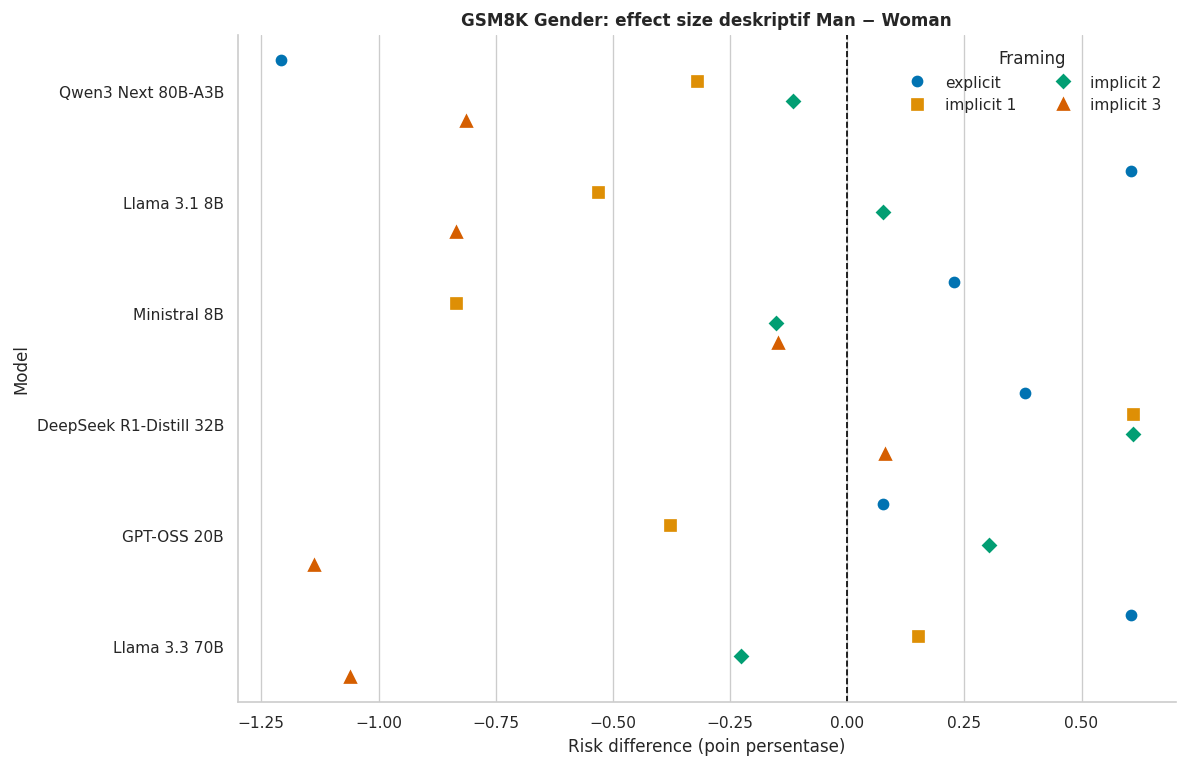

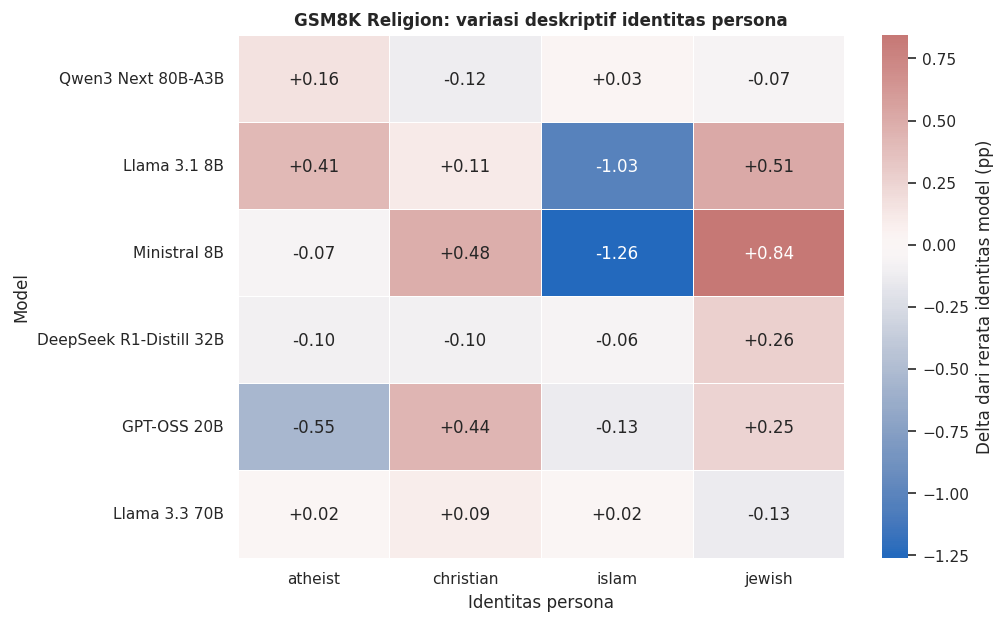

In [29]:
gender_effects = accuracy_effects[
    accuracy_effects["dataset"].eq("Gender") & accuracy_effects["family"].eq("gender_matched")
].copy()
gender_effects["condition"] = gender_effects["label"].str.split("|", regex=False).str[-1].str.strip()
condition_order = ["explicit", "implicit 1", "implicit 2", "implicit 3"]

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.pointplot(
    data=gender_effects,
    x="risk_difference_pp", y="model_label", hue="condition",
    hue_order=condition_order, order=[MODEL_LABELS[model] for model in MODEL_ORDER],
    dodge=0.55, join=False, markers=["o", "s", "D", "^"], ax=ax,
)
ax.axvline(0, color="black", lw=1, ls="--")
ax.set_title("GSM8K Gender: effect size deskriptif Man − Woman")
ax.set_xlabel("Risk difference (poin persentase)")
ax.set_ylabel("Model")
ax.legend(title="Framing", frameon=False, ncol=2)
fig.tight_layout()
save_figure(fig, "03_gender_risk_difference_six_models")
plt.show()

religion_identity = (
    summary[summary["dataset"].eq("Religion")]
    .groupby(["model", "model_label", "identity"], observed=True, as_index=False)["accuracy_pct"].mean()
)
religion_identity["model_centered_delta_pp"] = religion_identity.groupby("model_label")["accuracy_pct"].transform(lambda values: values - values.mean())
religion_identity.to_csv(TABLE_DIR / "religion_identity_descriptive_six_models.csv", index=False)
identity_heatmap = (
    religion_identity.pivot(index="model_label", columns="identity", values="model_centered_delta_pp")
    .reindex(index=[MODEL_LABELS[model] for model in MODEL_ORDER], columns=["atheist", "christian", "islam", "jewish"])
)
fig, ax = plt.subplots(figsize=(8.5, 5.3))
sns.heatmap(identity_heatmap, annot=True, fmt="+.2f", center=0, cmap="vlag", linewidths=0.5,
            cbar_kws={"label": "Delta dari rerata identitas model (pp)"}, ax=ax)
ax.set_title("GSM8K Religion: variasi deskriptif identitas persona")
ax.set_xlabel("Identitas persona")
ax.set_ylabel("Model")
fig.tight_layout()
save_figure(fig, "04_religion_identity_centered_six_models")
plt.show()

## 4. Analisis token

Analisis mempertahankan prompt, completion, reasoning, dan total token. Karena sumber hanya berisi agregat:

- `token_difference`: rerata token A dikurangi B;
- `token_ratio_a_over_b`: rasio rerata token A/B;
- tidak ada standardized effect atau p-value tanpa simpangan baku/data tingkat respons.

Token antarmodel tidak sepenuhnya sebanding karena tokenizer dan pelaporan reasoning dapat berbeda. Fokus inferensi substantif sebaiknya pada perbandingan persona **di dalam model**.

In [30]:
TOKEN_METRICS = ["avg_prompt_tokens", "avg_completion_tokens", "avg_reasoning_tokens", "avg_total_tokens"]
token_effect_rows = []
for (dataset, model), model_frame in summary.groupby(["dataset", "model"], observed=True):
    indexed = model_frame.set_index("persona")
    for comparison in comparisons[comparisons["dataset"].eq(dataset)].to_dict("records"):
        if comparison["persona_a"] not in indexed.index or comparison["persona_b"] not in indexed.index:
            continue
        row_a, row_b = indexed.loc[comparison["persona_a"]], indexed.loc[comparison["persona_b"]]
        for metric in TOKEN_METRICS:
            value_a, value_b = row_a[metric], row_b[metric]
            token_effect_rows.append({
                **comparison,
                "model": str(model), "model_label": MODEL_LABELS[str(model)],
                "token_metric": metric,
                "value_a": value_a, "value_b": value_b,
                "token_difference": value_a - value_b if pd.notna(value_a) and pd.notna(value_b) else np.nan,
                "token_ratio_a_over_b": value_a / value_b if pd.notna(value_a) and pd.notna(value_b) and value_b != 0 else np.nan,
                "inference_status": "descriptive_only_aggregate_source",
            })
token_effects = pd.DataFrame(token_effect_rows)
token_effects.to_csv(TABLE_DIR / "token_descriptive_effects_six_models.csv", index=False)

model_efficiency = (
    summary.groupby(["dataset", "model", "model_label"], observed=True, as_index=False)
    .agg(
        personas=("persona", "nunique"),
        responses=("total", "sum"),
        correct=("correct", "sum"),
        prompt_tokens_sum=("sum_prompt_tokens", lambda values: values.sum(min_count=1)),
        completion_tokens_sum=("sum_completion_tokens", lambda values: values.sum(min_count=1)),
        reasoning_tokens_sum=("sum_reasoning_tokens", lambda values: values.sum(min_count=1)),
        total_tokens_sum=("sum_total_tokens", lambda values: values.sum(min_count=1)),
        prompt_tokens_persona_mean=("avg_prompt_tokens", "mean"),
        completion_tokens_persona_mean=("avg_completion_tokens", "mean"),
        reasoning_tokens_persona_mean=("avg_reasoning_tokens", "mean"),
        total_tokens_persona_mean=("avg_total_tokens", "mean"),
        token_personas_available=("avg_total_tokens", "count"),
    )
)
weighted_model_accuracy = (
    summary.assign(weighted_accuracy=lambda frame: frame["accuracy_pct"] * frame["total"])
    .groupby(["dataset", "model"], observed=True)["weighted_accuracy"].sum()
    / summary.groupby(["dataset", "model"], observed=True)["total"].sum()
).rename("accuracy_pooled_pct").reset_index()
model_efficiency = model_efficiency.merge(
    weighted_model_accuracy, on=["dataset", "model"], validate="one_to_one"
)
model_efficiency["accuracy_implied_correct"] = (
    model_efficiency["accuracy_pooled_pct"] * model_efficiency["responses"] / 100
)
model_efficiency["correct_per_1k_completion_tokens"] = 1_000 * model_efficiency["accuracy_implied_correct"] / model_efficiency["completion_tokens_sum"]
model_efficiency["correct_per_1k_total_tokens"] = 1_000 * model_efficiency["accuracy_implied_correct"] / model_efficiency["total_tokens_sum"]
model_efficiency.to_csv(TABLE_DIR / "model_token_efficiency_six_models.csv", index=False)

display(Markdown("### Perbedaan completion token terbesar"))
display(
    token_effects[token_effects["token_metric"].eq("avg_completion_tokens")]
    .sort_values("token_difference", key=lambda values: values.abs(), ascending=False)
    [["dataset", "model_label", "label", "value_a", "value_b", "token_difference", "token_ratio_a_over_b"]]
    .head(25).style.format(precision=3)
)
display(Markdown("### Efisiensi token per model-dataset"))
display(model_efficiency.style.format(precision=3))

### Perbedaan completion token terbesar

,dataset,model_label,label,value_a,value_b,token_difference,token_ratio_a_over_b
997,Religion,DeepSeek R1-Distill 32B,Jewish implicit 1 − explicit,853.210,449.700,403.510,1.897
989,Religion,DeepSeek R1-Distill 32B,Islam implicit 2 − explicit,855.320,454.060,401.260,1.884
977,Religion,DeepSeek R1-Distill 32B,Christian implicit 2 − explicit,854.570,455.860,398.710,1.875
253,Gender,DeepSeek R1-Distill 32B,Woman implicit 1 − Neutral,829.290,432.120,397.170,1.919
993,Religion,DeepSeek R1-Distill 32B,Islam implicit 3 − explicit,847.450,454.060,393.390,1.866
277,Gender,DeepSeek R1-Distill 32B,Woman implicit 1 − explicit,829.290,436.440,392.850,1.900
1005,Religion,DeepSeek R1-Distill 32B,Jewish implicit 3 − explicit,841.290,449.700,391.590,1.871
265,Gender,DeepSeek R1-Distill 32B,Man implicit 1 − explicit,815.320,425.120,390.200,1.918
981,Religion,DeepSeek R1-Distill 32B,Christian implicit 3 − explicit,846.000,455.860,390.140,1.856
969,Religion,DeepSeek R1-Distill 32B,Atheist implicit 3 − explicit,851.180,462.260,388.920,1.841


### Efisiensi token per model-dataset

,dataset,model,model_label,personas,responses,correct,prompt_tokens_sum,completion_tokens_sum,reasoning_tokens_sum,total_tokens_sum,prompt_tokens_persona_mean,completion_tokens_persona_mean,reasoning_tokens_persona_mean,total_tokens_persona_mean,token_personas_available,accuracy_pooled_pct,accuracy_implied_correct,correct_per_1k_completion_tokens,correct_per_1k_total_tokens
0,Gender,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,9,11868.000,10757.000,5548638.000,11413371.000,0.000,16962009.000,467.503,961.693,0.000,1429.198,9,93.174,11057.900,0.969,0.652
1,Gender,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,9,11871.000,9923.000,3942121.000,2278303.000,0.000,6220424.000,332.092,191.952,0.000,524.050,9,83.590,9923.002,4.355,1.595
2,Gender,mistralai_ministral-8b-2512,Ministral 8B,9,11869.000,11071.000,6550690.000,3074525.000,0.000,9625215.000,620.891,291.423,0.000,912.312,8,93.277,11071.000,3.601,1.150
3,Gender,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,9,11869.000,10945.000,2587025.000,7867590.000,0.000,10454615.000,217.951,662.857,0.000,880.809,9,92.214,10944.927,1.391,1.047
4,Gender,openai_gpt-oss-20b,GPT-OSS 20B,9,11870.000,11251.000,7987834.000,3399309.000,0.000,11387143.000,672.898,286.382,0.000,959.281,9,94.785,11251.000,3.310,0.988
5,Gender,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,9,11870.000,11053.000,4513340.000,2234814.000,0.000,6748154.000,380.206,188.273,0.000,568.481,9,93.117,11053.001,4.946,1.638
6,Religion,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,16,21104.000,20166.000,nan,nan,nan,nan,1245.141,1030.467,663.898,2275.607,16,95.555,20165.997,nan,nan
7,Religion,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,16,21104.000,17289.000,nan,nan,nan,nan,538.169,217.346,0.000,755.514,16,81.923,17289.000,nan,nan
8,Religion,mistralai_ministral-8b-2512,Ministral 8B,16,21104.000,18478.000,nan,nan,nan,nan,1101.434,298.789,0.000,1400.223,16,87.557,18478.000,nan,nan
9,Religion,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,16,21104.000,19637.000,nan,nan,nan,nan,429.995,744.836,751.888,1174.829,16,93.049,19636.999,nan,nan


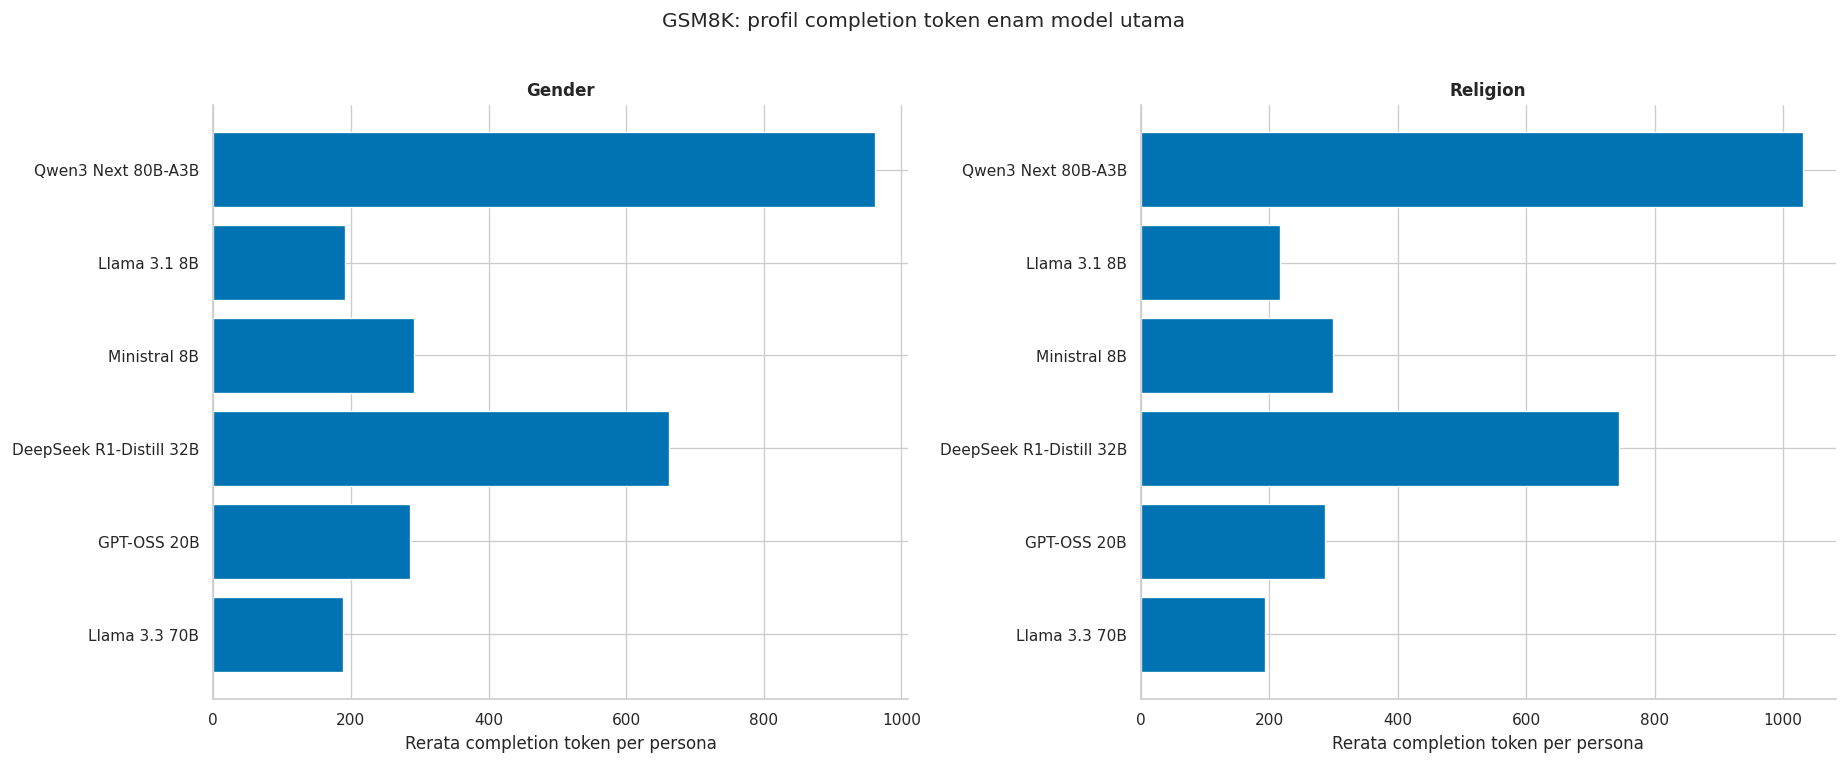

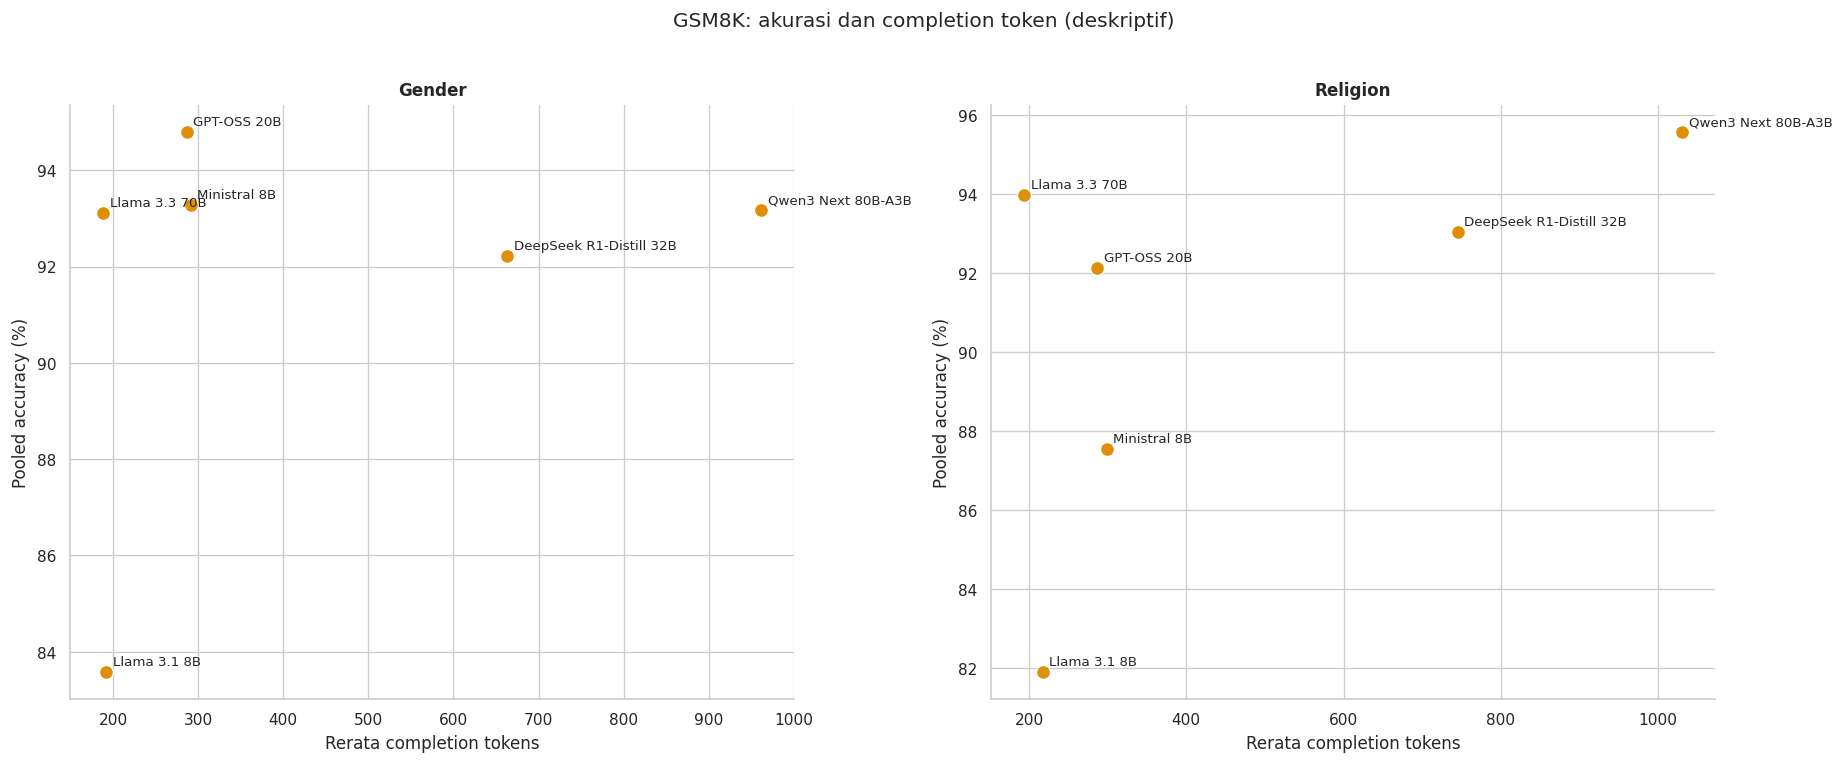

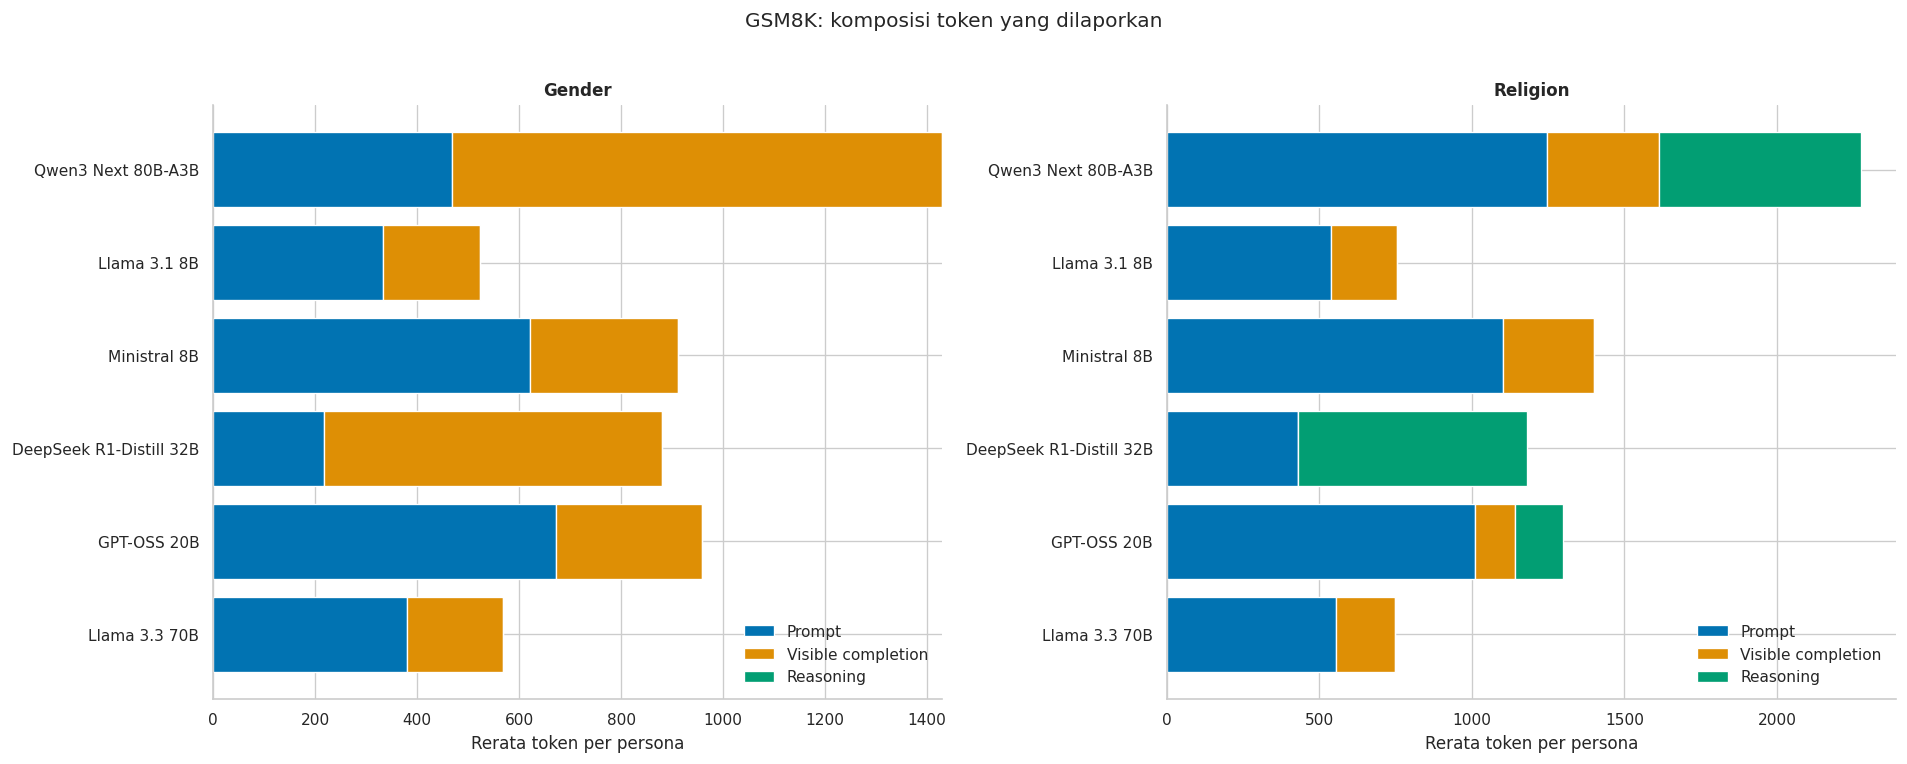

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15.5, 6.2))
for ax, dataset in zip(axes, ["Gender", "Religion"]):
    subset = model_efficiency[model_efficiency["dataset"].eq(dataset)].copy()
    subset["model_label"] = pd.Categorical(
        subset["model_label"], [MODEL_LABELS[model] for model in MODEL_ORDER], ordered=True
    )
    subset = subset.sort_values("model_label", ascending=False)
    ax.barh(subset["model_label"].astype(str), subset["completion_tokens_persona_mean"], color=sns.color_palette("colorblind")[0])
    ax.set_title(dataset)
    ax.set_xlabel("Rerata completion token per persona")
    ax.set_ylabel("")
fig.suptitle("GSM8K: profil completion token enam model utama", y=1.02)
fig.tight_layout()
save_figure(fig, "05_completion_token_profile_six_models")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15.5, 6.2))
for ax, dataset in zip(axes, ["Gender", "Religion"]):
    subset = model_efficiency[model_efficiency["dataset"].eq(dataset)]
    ax.scatter(subset["completion_tokens_persona_mean"], subset["accuracy_pooled_pct"],
               s=70, color=sns.color_palette("colorblind")[1], edgecolor="white", linewidth=0.8)
    for row in subset.itertuples():
        ax.annotate(row.model_label, (row.completion_tokens_persona_mean, row.accuracy_pooled_pct),
                    xytext=(4, 4), textcoords="offset points", fontsize=8)
    ax.set_title(dataset)
    ax.set_xlabel("Rerata completion tokens")
    ax.set_ylabel("Pooled accuracy (%)")
fig.suptitle("GSM8K: akurasi dan completion token (deskriptif)", y=1.02)
fig.tight_layout()
save_figure(fig, "06_accuracy_vs_completion_six_models")
plt.show()

# Reasoning tokens may be a component of completion tokens depending on provider.
composition = model_efficiency.copy()
composition["visible_completion_tokens_persona_mean"] = (
    composition["completion_tokens_persona_mean"] - composition["reasoning_tokens_persona_mean"]
).clip(lower=0)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.2))
colors = sns.color_palette("colorblind", 3)
for ax, dataset in zip(axes, ["Gender", "Religion"]):
    subset = composition[composition["dataset"].eq(dataset)].copy()
    subset["model_label"] = pd.Categorical(
        subset["model_label"], [MODEL_LABELS[model] for model in MODEL_ORDER], ordered=True
    )
    subset = subset.sort_values("model_label", ascending=False)
    y = np.arange(len(subset))
    left = np.zeros(len(subset))
    for column, label, color in [
        ("prompt_tokens_persona_mean", "Prompt", colors[0]),
        ("visible_completion_tokens_persona_mean", "Visible completion", colors[1]),
        ("reasoning_tokens_persona_mean", "Reasoning", colors[2]),
    ]:
        values = subset[column].fillna(0).to_numpy()
        ax.barh(y, values, left=left, label=label, color=color)
        left += values
    ax.set_yticks(y, subset["model_label"].astype(str))
    ax.set_title(dataset)
    ax.set_xlabel("Rerata token per persona")
    ax.legend(frameon=False)
fig.suptitle("GSM8K: komposisi token yang dilaporkan", y=1.02)
fig.tight_layout()
save_figure(fig, "07_token_composition_six_models")
plt.show()

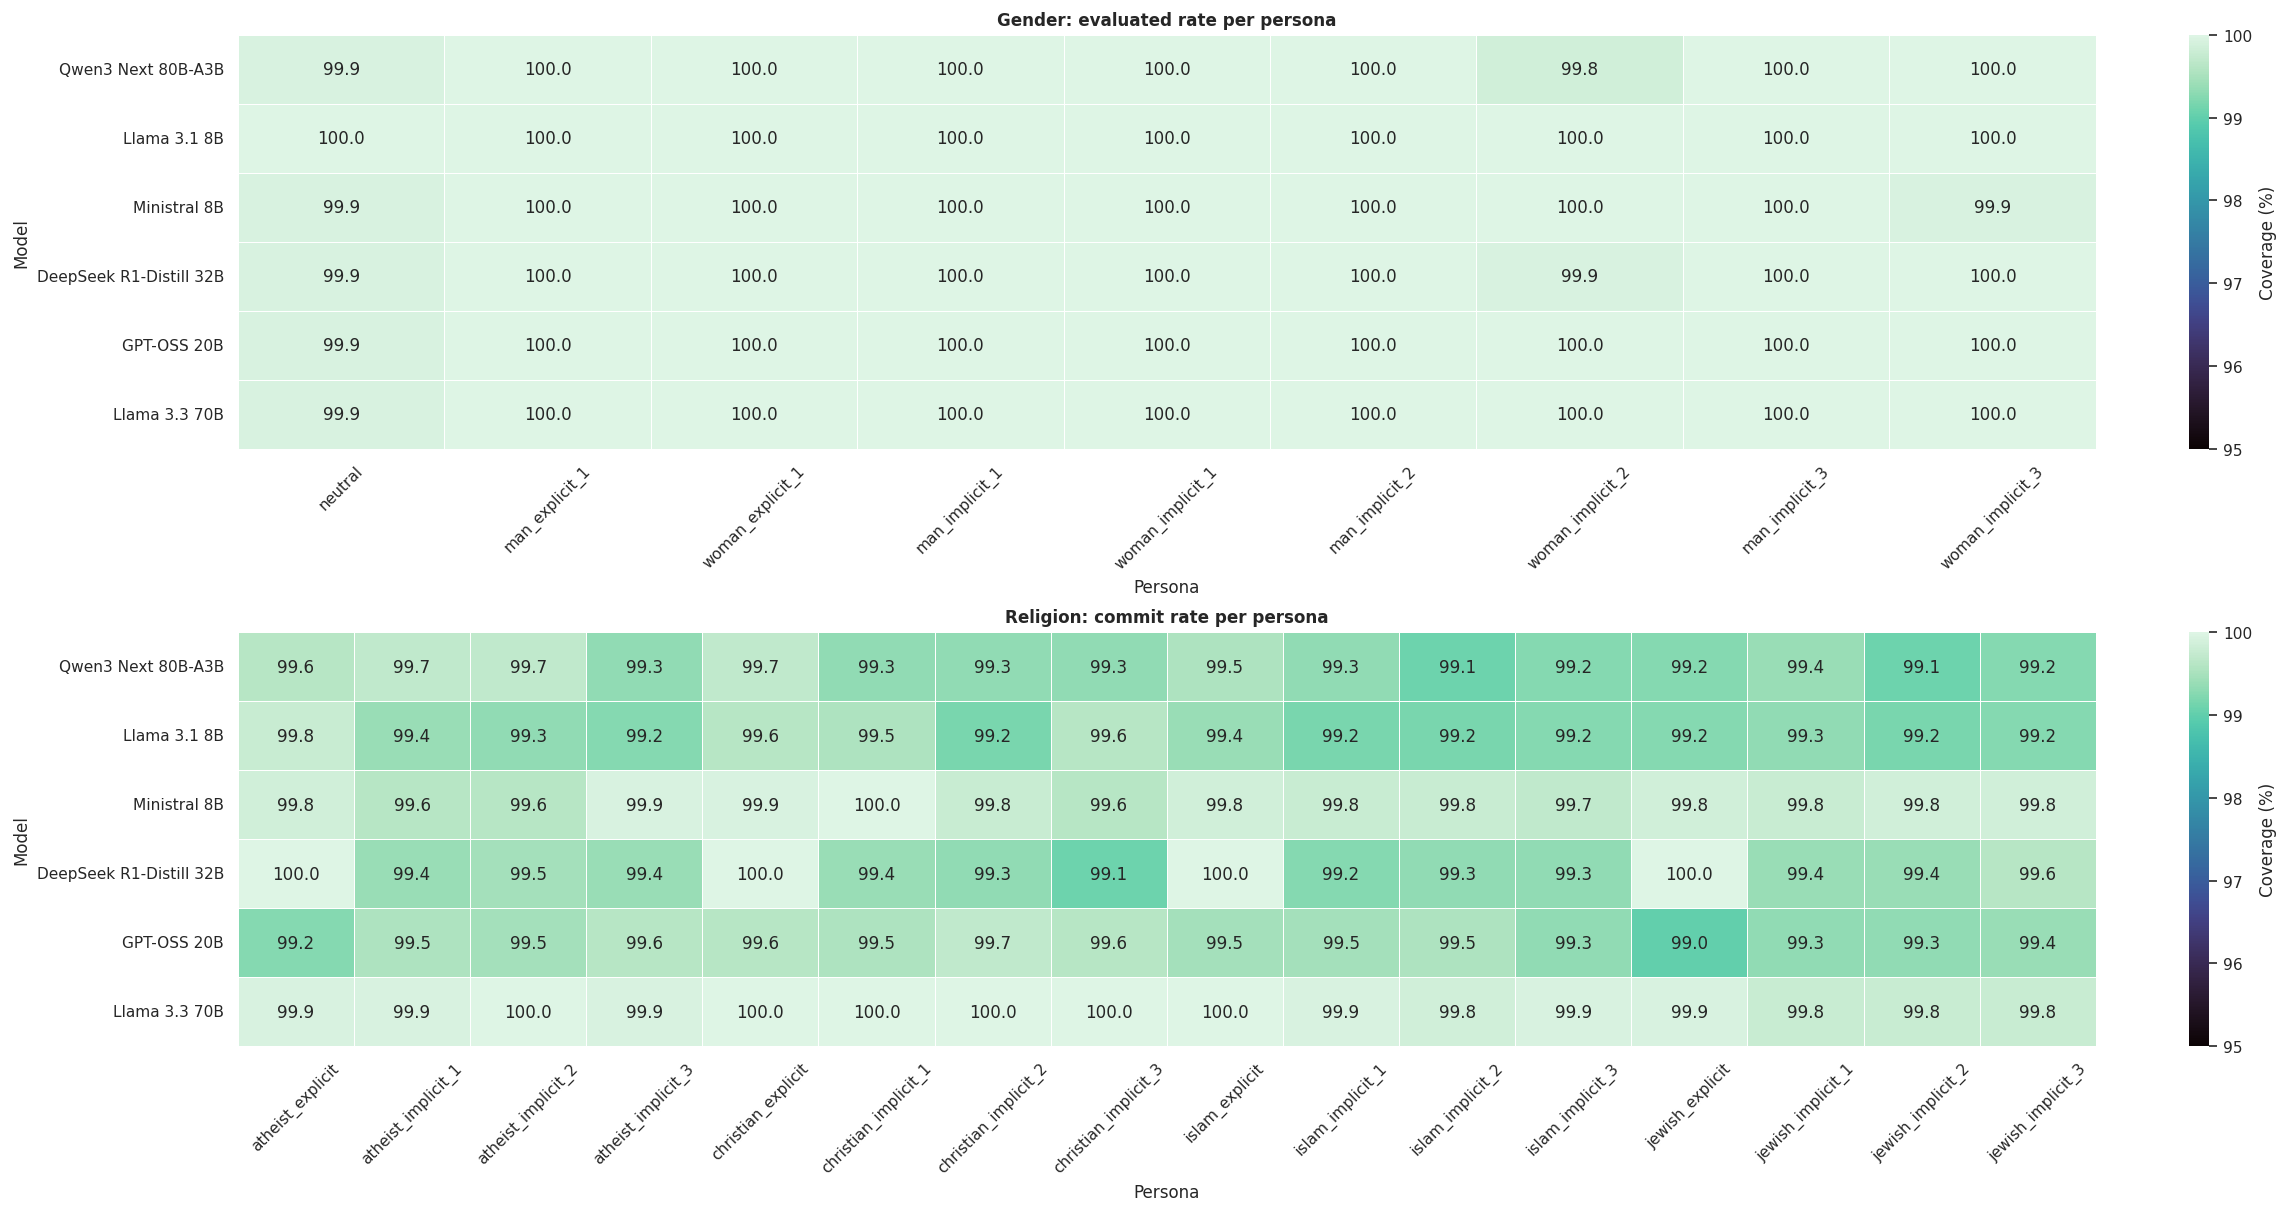

,dataset,model,model_label,coverage_metric,min_coverage_pct,max_coverage_pct,mean_coverage_pct,coverage_range_pp
0,Gender,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Evaluated rate,99.8484,100.0000,99.9747,0.1516
1,Gender,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,Evaluated rate,100.0000,100.0000,100.0000,0.0000
2,Gender,mistralai_ministral-8b-2512,Ministral 8B,Evaluated rate,99.9242,100.0000,99.9832,0.0758
3,Gender,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,Evaluated rate,99.9242,100.0000,99.9832,0.0758
4,Gender,openai_gpt-oss-20b,GPT-OSS 20B,Evaluated rate,99.9242,100.0000,99.9916,0.0758
5,Gender,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,Evaluated rate,99.9242,100.0000,99.9916,0.0758
6,Religion,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Commit rate,99.0902,99.6967,99.3840,0.6065
7,Religion,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,Commit rate,99.1660,99.7726,99.3508,0.6066
8,Religion,mistralai_ministral-8b-2512,Ministral 8B,Commit rate,99.6209,100.0000,99.7963,0.3791
9,Religion,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,Commit rate,99.0902,100.0000,99.5214,0.9098


In [32]:
coverage = summary.copy()
coverage["coverage_metric_pct"] = np.where(
    coverage["dataset"].eq("Religion"), coverage["commit_rate_pct"], coverage["evaluated_rate_pct"]
)
coverage["coverage_metric"] = np.where(
    coverage["dataset"].eq("Religion"), "Commit rate", "Evaluated rate"
)

fig, axes = plt.subplots(2, 1, figsize=(19, 10), constrained_layout=True)
for ax, dataset, order in zip(axes, ["Gender", "Religion"], [gender_order, religion_order]):
    matrix = (
        coverage[coverage["dataset"].eq(dataset)]
        .pivot(index="model_label", columns="persona", values="coverage_metric_pct")
        .reindex(index=[MODEL_LABELS[model] for model in MODEL_ORDER], columns=order)
    )
    sns.heatmap(matrix, annot=True, fmt=".1f", cmap="mako", vmin=95, vmax=100,
                linewidths=0.3, cbar_kws={"label": "Coverage (%)"}, ax=ax)
    metric = "evaluated rate" if dataset == "Gender" else "commit rate"
    ax.set_title(f"{dataset}: {metric} per persona")
    ax.set_xlabel("Persona")
    ax.set_ylabel("Model")
    ax.tick_params(axis="x", rotation=45)
save_figure(fig, "08_coverage_heatmap_six_models")
plt.show()

coverage_summary = (
    coverage.groupby(["dataset", "model", "model_label", "coverage_metric"], observed=True, as_index=False)
    .agg(
        min_coverage_pct=("coverage_metric_pct", "min"),
        max_coverage_pct=("coverage_metric_pct", "max"),
        mean_coverage_pct=("coverage_metric_pct", "mean"),
        coverage_range_pp=("coverage_metric_pct", lambda values: values.max() - values.min()),
    )
)
coverage_summary.to_csv(TABLE_DIR / "coverage_summary_six_models.csv", index=False)
display(coverage_summary.style.format(precision=4))

## 5. Pedoman penggunaan di TA/paper

### Tabel utama

- `accuracy_by_persona_six_models.csv`: akurasi, Wilson CI, coverage, dan token per persona.
- `explicit_implicit_descriptive_six_models.csv`: rerata descriptive explicit/implicit per identitas.
- `marginal_accuracy_effects_six_models.csv`: risk difference, Cohen's h, dan marginal odds ratio.
- `token_descriptive_effects_six_models.csv`: selisih dan rasio token antar-persona.
- `model_token_efficiency_six_models.csv`: pooled accuracy dan token per model-dataset.
- `coverage_summary_six_models.csv`: rentang coverage dalam setiap model.
- `source_manifest.csv`: SHA-256 dan metadata dua sumber.

### Batas klaim

1. Gunakan istilah **sensitivitas performa terhadap prompt persona**, bukan langsung menyatakan diskriminasi atau hubungan kausal.
2. Risk difference adalah effect size utama karena paling mudah ditafsirkan dalam poin persentase.
3. Cohen's h dan odds ratio merupakan effect size marginal; keduanya tidak memanfaatkan pairing pertanyaan.
4. Jangan menyebut effect sebagai signifikan/tidak signifikan dari notebook ini. Untuk inferensi berpasangan diperlukan CSV tingkat pertanyaan yang menghasilkan angka agregat yang sama.
5. Gender hanya memiliki evaluated rate; Religion memiliki commit rate. Kedua metrik tersebut tidak boleh disamakan tanpa penjelasan.
6. Reasoning token bernilai nol pada CSV Gender, kemungkinan karena provider/parser memasukkannya ke completion atau tidak melaporkannya secara terpisah.
7. Tokenizer dan format reasoning berbeda antar-model. Analisis token lintas model bersifat deskriptif.
8. Rerata tiga implicit persona memberi bobot sama pada setiap formulasi dan bukan tiga sampel independen.

In [ ]:
largest_gender = (
    accuracy_effects[
        accuracy_effects["dataset"].eq("Gender") & accuracy_effects["family"].eq("gender_matched")
    ]
    .sort_values("risk_difference_pp", key=lambda values: values.abs(), ascending=False)
    .iloc[0]
)
largest_religion = (
    accuracy_effects[
        accuracy_effects["dataset"].eq("Religion") & accuracy_effects["family"].eq("religion_identity_matched")
    ]
    .sort_values("risk_difference_pp", key=lambda values: values.abs(), ascending=False)
    .iloc[0]
)

display(Markdown(
    "### Ringkasan audit otomatis\n\n"
    f"- Input: **150 baris** = 54 Gender + 96 Religion, masing-masing tepat enam model utama.\n"
    f"- Effect Gender matched terbesar: **{largest_gender['model_label']}**, "
    f"{largest_gender['label']} = **{largest_gender['risk_difference_pp']:+.2f} pp**, "
    f"Cohen's h = {largest_gender['cohen_h']:+.3f}.\n"
    f"- Effect Religion matched terbesar: **{largest_religion['model_label']}**, "
    f"{largest_religion['label']} = **{largest_religion['risk_difference_pp']:+.2f} pp**, "
    f"Cohen's h = {largest_religion['cohen_h']:+.3f}.\n"
    "- Seluruh effect bersifat deskriptif karena sumber tidak memuat hasil per question_id."
))

output_index = []
for path in sorted(TABLE_DIR.glob("*.csv")):
    frame = pd.read_csv(path)
    output_index.append({
        "type": "table", "file": path.name, "rows": len(frame),
        "columns": len(frame.columns), "bytes": path.stat().st_size,
    })
for path in sorted(FIGURE_DIR.glob("*")):
    output_index.append({
        "type": "figure", "file": path.name, "rows": np.nan,
        "columns": np.nan, "bytes": path.stat().st_size,
    })
output_index = pd.DataFrame(output_index)
output_index.to_csv(OUTPUT_ROOT / "output_index.csv", index=False)
display(output_index)

# Final gates: no seventh model and no silent schema drift.
assert set(summary["model"].astype(str)) == set(MODEL_ORDER)
assert summary.groupby("dataset", observed=True)["model"].nunique().to_dict() == {"Gender": 6, "Religion": 6}
assert summary.groupby("dataset").size().to_dict() == {"Gender": 54, "Religion": 96}
assert accuracy_effects["model"].nunique() == 6
assert token_effects["model"].nunique() == 6
assert not accuracy_effects["model"].isin(set(MODEL_LABELS) - set(MODEL_ORDER)).any()
assert len(list(FIGURE_DIR.glob("*.png"))) >= 8
assert len(list(FIGURE_DIR.glob("*.svg"))) >= 8
assert (TABLE_DIR / "source_manifest.csv").exists()
print("SEMUA VALIDASI ENAM MODEL UTAMA LULUS")

### Ringkasan audit otomatis

- Input: **150 baris** = 54 Gender + 96 Religion, masing-masing tepat enam model utama.
- Effect Gender matched terbesar: **Qwen3 Next 80B-A3B**, Man − Woman | explicit = **-1.21 pp**, Cohen's h = -0.049.
- Effect Religion matched terbesar: **Ministral 8B**, Islam − Jewish | implicit 1 = **-4.70 pp**, Cohen's h = -0.132.
- Seluruh effect bersifat deskriptif karena sumber tidak memuat hasil per question_id.

,type,file,rows,columns,bytes
0,table,accuracy_by_persona_six_models.csv,150.0000,31.0000,42104
1,table,coverage_summary_six_models.csv,12.0000,8.0000,1552
2,table,data_inventory_six_models.csv,12.0000,12.0000,1761
3,table,explicit_implicit_descriptive_six_models.csv,78.0000,15.0000,12514
4,table,marginal_accuracy_effects_six_models.csv,324.0000,19.0000,98472
5,table,model_token_efficiency_six_models.csv,12.0000,19.0000,2708
6,table,religion_identity_descriptive_six_models.csv,24.0000,5.0000,2137
7,table,source_consistency_audit.csv,150.0000,13.0000,23177
8,table,source_manifest.csv,2.0000,5.0000,372
9,table,token_descriptive_effects_six_models.csv,"1,296.0000",13.0000,309228


SEMUA VALIDASI ENAM MODEL UTAMA LULUS


: 